# Análise Exploratória — Observatório Macro-Financeiro

Notebook de exploração das séries oficiais do SGS/BCB (2020–2023).


In [1]:

%cd /content
!test -d observatorio-macro-financeiro || git clone https://github.com/carolsscv/observatorio-macro-financeiro.git
%cd /content/observatorio-macro-financeiro
!ls


/content
/content/observatorio-macro-financeiro
app.py			observatorio-macro-financeiro  src
data			PITCH.md		       TRELLO_CARDS.md
INSTRUCOES_RAPIDAS.txt	README.md
notebooks		requirements.txt


In [ ]:
%cd /content/observatorio-macro-financeiro
!pip install -r requirements.txt

In [3]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.etl import run_etl, validate_data

df = run_etl()
df.head()

,date,selic_meta,ipca_mensal,ipca_12m,dolar_ptax,ibc_br,juro_real_ex_post
0,2020-01-01,4.500000,0.21,4.19,4.149464,97.58153,0.297533
1,2020-02-01,4.293103,0.25,4.01,4.341011,97.71989,0.272189
2,2020-03-01,4.040323,0.07,3.30,4.883855,91.23397,0.716672
3,2020-04-01,3.750000,-0.31,2.40,5.325580,82.93935,1.318359
4,2020-05-01,3.145161,-0.38,1.88,5.643445,85.45553,1.241815


## 1. Estatísticas descritivas e qualidade

In [4]:
display(df.describe().T)
diagnostico = validate_data(df)
diagnostico

,count,mean,min,25%,50%,75%,max,std
date,48,2021-12-15 23:00:00,2020-01-01 00:00:00,2020-12-24 06:00:00,2021-12-16 12:00:00,2022-12-08 18:00:00,2023-12-01 00:00:00,NaN
selic_meta,48.0,8.312437,2.0,3.320565,9.056452,13.387097,13.75,4.913846
ipca_mensal,48.0,0.505417,-0.68,0.24,0.535,0.86,1.62,0.476619
ipca_12m,48.0,6.36,1.88,4.1375,5.4,9.1625,12.13,3.057622
dolar_ptax,48.0,5.17765,4.149464,4.979223,5.206071,5.375925,5.651391,0.312066
ibc_br,48.0,98.328948,82.93935,96.94811,98.84307,101.421253,104.92651,4.507739
juro_real_ex_post,48.0,1.882565,-4.349023,-2.26367,0.415583,7.288777,10.265607,4.785529


{'linhas': 48,
 'duplicados': 0,
 'nulos_por_coluna': {'date': 0,
  'selic_meta': 0,
  'ipca_mensal': 0,
  'ipca_12m': 0,
  'dolar_ptax': 0,
  'ibc_br': 0,
  'juro_real_ex_post': 0},
 'data_inicial': '2020-01-01',
 'data_final': '2023-12-01'}

## 2. Tratamento de nulos e duplicidades

In [5]:
print("Nulos por coluna:")
display(df.isna().sum().to_frame("quantidade"))
print("Duplicidades:", df.duplicated().sum())
df_limpo = df.drop_duplicates(subset=["date"]).sort_values("date").copy()
df_limpo["date"] = pd.to_datetime(df_limpo["date"], errors="coerce")
for coluna in df_limpo.columns:
    if coluna != "date":
        df_limpo[coluna] = pd.to_numeric(df_limpo[coluna], errors="coerce")
df_limpo = df_limpo.dropna(subset=["date"])
display(df_limpo.isna().sum().to_frame("nulos após padronização"))

Nulos por coluna:


,quantidade
date,0
selic_meta,0
ipca_mensal,0
ipca_12m,0
dolar_ptax,0
ibc_br,0
juro_real_ex_post,0


Duplicidades: 0


,nulos após padronização
date,0
selic_meta,0
ipca_mensal,0
ipca_12m,0
dolar_ptax,0
ibc_br,0
juro_real_ex_post,0


## 3. Detecção exploratória de outliers (IQR)

In [6]:
numericas = df_limpo.select_dtypes(include="number")
resumo_outliers = []
for coluna in numericas.columns:
    q1, q3 = numericas[coluna].quantile([0.25, 0.75])
    iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    qtd = ((numericas[coluna] < inferior) | (numericas[coluna] > superior)).sum()
    resumo_outliers.append({"variavel": coluna, "limite_inferior": inferior,
                            "limite_superior": superior, "outliers_iqr": int(qtd)})
pd.DataFrame(resumo_outliers)

,variavel,limite_inferior,limite_superior,outliers_iqr
0,selic_meta,-11.779234,28.486895,0
1,ipca_mensal,-0.690000,1.790000,0
2,ipca_12m,-3.400000,16.700000,0
3,dolar_ptax,4.384169,5.970978,2
4,ibc_br,90.238396,108.130966,3
5,juro_real_ex_post,-16.592340,21.617447,0


## 4. Distribuições e dispersão

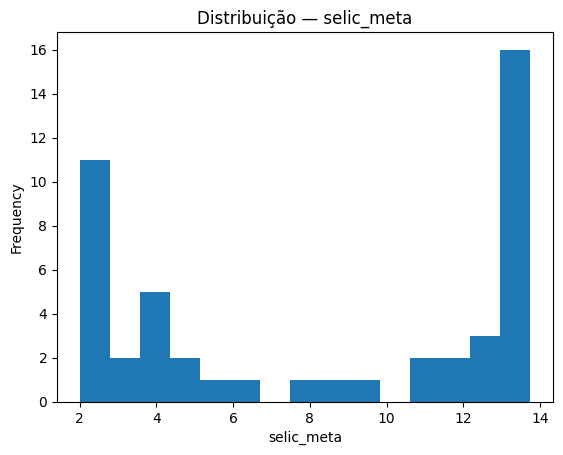

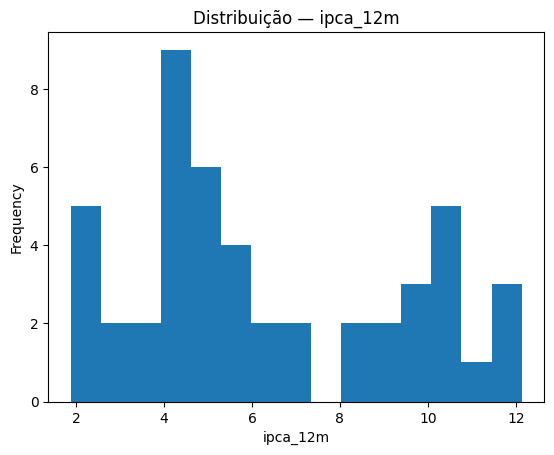

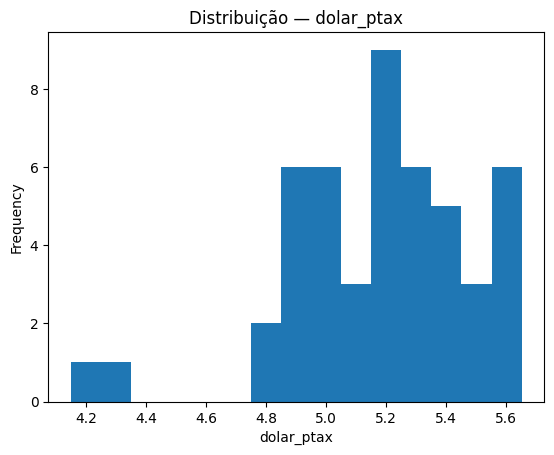

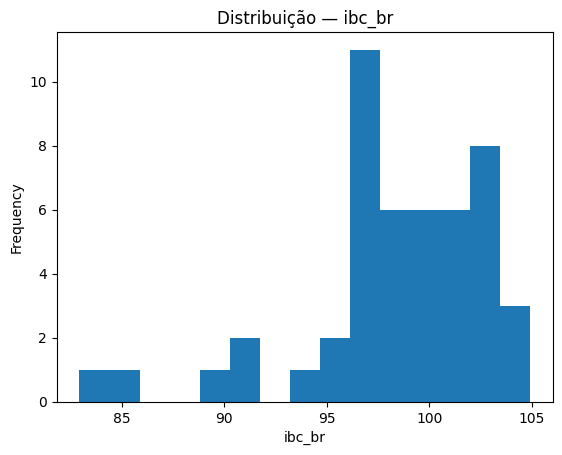

In [7]:
colunas = ["selic_meta", "ipca_12m", "dolar_ptax", "ibc_br"]
for coluna in colunas:
    ax = df_limpo[coluna].dropna().plot(kind="hist", bins=15, title=f"Distribuição — {coluna}")
    ax.set_xlabel(coluna)
    plt.show()

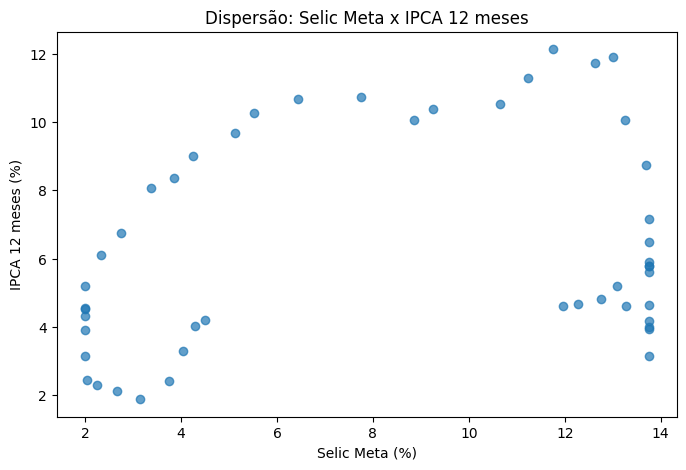

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df_limpo["selic_meta"], df_limpo["ipca_12m"], alpha=0.7)
ax.set_title("Dispersão: Selic Meta x IPCA 12 meses")
ax.set_xlabel("Selic Meta (%)")
ax.set_ylabel("IPCA 12 meses (%)")
plt.show()

## 5. Correlação

,selic_meta,ipca_mensal,ipca_12m,dolar_ptax,ibc_br
selic_meta,1.000000,-0.178000,0.264350,-0.313963,0.734218
ipca_mensal,-0.178000,1.000000,0.420959,0.141814,0.144092
ipca_12m,0.264350,0.420959,1.000000,0.107103,0.259483
dolar_ptax,-0.313963,0.141814,0.107103,1.000000,-0.319680
ibc_br,0.734218,0.144092,0.259483,-0.319680,1.000000


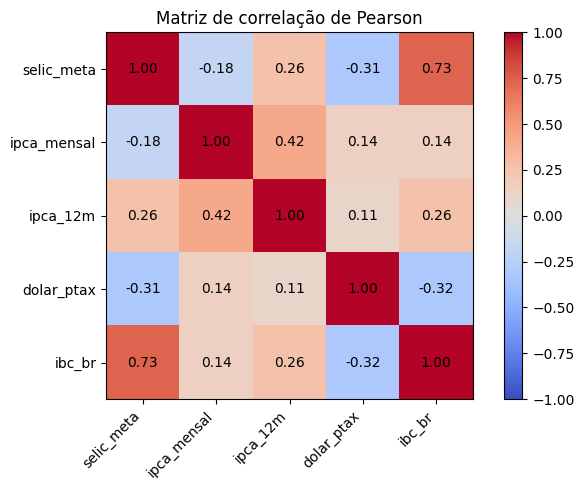

In [9]:
corr = df_limpo[["selic_meta", "ipca_mensal", "ipca_12m",
                    "dolar_ptax", "ibc_br"]].corr(method="pearson")
display(corr)
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr.index)), corr.index)
for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im, ax=ax)
ax.set_title("Matriz de correlação de Pearson")
plt.tight_layout()
plt.show()

## 6. Conclusão da EDA

A base analisada contém **48 observações mensais**, de janeiro de 2020 a dezembro de 2023. No diagnóstico registrado, não foram identificados valores ausentes ou linhas duplicadas.

### Principais observações

1. **Selic e inflação:** a Selic Meta apresentou média de 8,31% no período, com mínimo de 2,00% e máximo de 13,75%. O IPCA acumulado em 12 meses teve média de 6,36%, variando de 1,88% a 12,13%. As séries mostram que o período reuniu diferentes regimes de juros e inflação; os valores médios, isoladamente, não demonstram relação de causa e efeito.

2. **Câmbio e atividade econômica:** o dólar PTAX teve média de R$ 5,18, com valores entre R$ 4,15 e R$ 5,65. O IBC-Br variou de 82,94 a 104,93 pontos. A análise pelo critério do intervalo interquartil (IQR) sinalizou 2 observações atípicas para o dólar e 3 para o IBC-Br; esses pontos devem ser interpretados como ocorrências a investigar, não como erros automaticamente.

3. **Correlações:** a maior correlação positiva observada foi entre Selic Meta e IBC-Br (r = 0,73). Entre as correlações negativas, destacaram-se dólar PTAX e IBC-Br (r = -0,32) e Selic Meta e dólar PTAX (r = -0,31). Correlação mede associação linear e **não implica causalidade**.

### Limitações

A análise é exploratória e utiliza observações mensais de 2020 a 2023. As correlações são descritivas, não controlam outros fatores econômicos e não devem ser interpretadas como evidência causal. Os indicadores possuem naturezas e escalas distintas; por isso, suas comparações devem respeitar as definições das séries do Banco Central.

### Fonte

Banco Central do Brasil (BCB), Sistema Gerenciador de Séries Temporais (SGS), conforme as séries e procedimentos documentados no código ETL do projeto.
